# NYC Housing × Transportation — Milestone 1


## 0. Project Overview & Datasets

**Housing:** Housing Maintenance Code Complaints and Problems (HPD)
https://data.cityofnewyork.us/d/ygpa-z7cr

**Transportation:** Serious Injury Response, Tracking & Analysis Program (SIRTA, NYC DOT)
https://data.cityofnewyork.us/d/xeqp-qz8h

**Integration plan:** ZIP code × year (2022 onward); borough × month for seasonal analysis.

## 1. Setup & Imports

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import plotly
import dash

print("pandas", pd.__version__)
print("All libraries loaded")

pandas 3.0.6
All libraries loaded


## 2. Data Loading

In [36]:
import os
import pandas as pd
from urllib.parse import urlencode

# Dataset IDs from each dataset's NYC Open Data URL
housing_id = 'ygpa-z7cr'     # HPD Housing Maintenance Code Complaints and Problems
transport_id = 'xeqp-qz8h'   # SIRTA - Serious Injury Crashes (NYC DOT)

base_url = 'https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download'
api_url = 'https://data.cityofnewyork.us/resource/{}.csv'

# Local copies of the raw data (not pushed to GitHub, see .gitignore)
sirta_cache = '../data/raw/sirta_raw.pkl'
hpd_cache = '../data/raw/hpd_2022_2025.pkl'

# SIRTA is small (~13k rows), so we load the full dataset (Listing 1)
if os.path.exists(sirta_cache):
    df_transport = pd.read_pickle(sirta_cache)
else:
    df_transport = pd.read_csv(base_url.format(transport_id), low_memory=False)
    os.makedirs('../data/raw', exist_ok=True)
    df_transport.to_pickle(sirta_cache)

print(df_transport.shape)
df_transport.head()

(13754, 23)


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,...,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# HPD has ~14M rows, so before loading we count rows per year to choose a safe filter (Listing 2)
params = {
    '$select': 'date_extract_y(received_date) AS year, count(*) AS n_rows',
    '$where': "received_date >= '2022-01-01T00:00:00'",
    '$group': 'year',
    '$order': 'year'
}
hpd_counts = pd.read_csv(api_url.format(housing_id) + '?' + urlencode(params))
hpd_counts

,year,n_rows
0,2022,733471
1,2023,747466
2,2024,823169
3,2025,856280
4,2026,748418


**Why we load a filtered sample of HPD:** The full dataset has ~14M rows (2001–present) and would crash a laptop notebook. We keep **2022–2025** because these are the full years that overlap with SIRTA (which starts in 2022); 2026 is excluded because it is incomplete in both datasets. We also select only the 17 columns relevant to our research questions and load one year at a time to stay within the API's `$limit`.

In [38]:
# Columns we need from HPD (geography, time, complaint categories, status)
hpd_columns = [
    'received_date', 'problem_id', 'complaint_id', 'borough', 'post_code',
    'latitude', 'longitude', 'community_board', 'nta', 'unit_type', 'space_type',
    'type', 'major_category', 'minor_category', 'complaint_status',
    'problem_status', 'problem_duplicate_flag'
]
# Repeated text columns are stored as 'category' to reduce memory use
category_columns = ['borough', 'unit_type', 'space_type', 'type', 'major_category',
                    'minor_category', 'complaint_status', 'problem_status',
                    'problem_duplicate_flag']

if os.path.exists(hpd_cache):
    # Load the saved local copy (seconds instead of ~9 minutes)
    df_housing = pd.read_pickle(hpd_cache)
else:
    # Download one year at a time (Listing 2); each year has < 1M rows
    yearly_frames = []
    for year in [2022, 2023, 2024, 2025]:
        params = {
            '$select': ', '.join(hpd_columns),
            '$where': f"received_date >= '{year}-01-01T00:00:00' AND received_date < '{year + 1}-01-01T00:00:00'",
            '$limit': 1000000,      # each year has < 1M rows, so nothing is cut off
            '$order': ':id'         # stable order so the download is repeatable
        }
        df_year = pd.read_csv(api_url.format(housing_id) + '?' + urlencode(params),
                              low_memory=False, dtype={'post_code': str})
        df_year[category_columns] = df_year[category_columns].astype('category')
        yearly_frames.append(df_year)
        print(year, df_year.shape)
    df_housing = pd.concat(yearly_frames, ignore_index=True)
    os.makedirs('../data/raw', exist_ok=True)
    df_housing.to_pickle(hpd_cache)

print('Total:', df_housing.shape)
df_housing.head()

Total: (3160386, 17)


,received_date,problem_id,complaint_id,borough,post_code,latitude,longitude,community_board,nta,unit_type,space_type,type,major_category,minor_category,complaint_status,problem_status,problem_duplicate_flag
0,2022-01-16T00:54:39.000,22273633,11054566,MANHATTAN,10029,40.793701,-73.941804,11,East Harlem (North),APARTMENT,BEDROOM,EMERGENCY,HEAT/HOT WATER,APARTMENT ONLY,CLOSE,CLOSE,N
1,2022-01-16T00:54:39.000,22273634,11054566,MANHATTAN,10029,40.793701,-73.941804,11,East Harlem (North),APARTMENT,BEDROOM,EMERGENCY,DOOR/WINDOW,WINDOW PANE,CLOSE,CLOSE,N
2,2022-01-23T22:05:21.000,22307373,11078555,MANHATTAN,10044,40.757748,-73.953581,8,Upper East Side-Lenox Hill-Roosevelt Island,APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N
3,2022-02-04T13:40:22.000,22359869,11107818,MANHATTAN,10032,40.837506,-73.945343,12,Washington Heights (South),APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N
4,2022-02-04T13:40:22.000,22359870,11107818,MANHATTAN,10032,40.837506,-73.945343,12,Washington Heights (South),APARTMENT,BATHROOM,EMERGENCY,PLUMBING,BASIN/SINK,CLOSE,CLOSE,N


## 3. Exploratory Data Analysis (EDA)

### 3.1 Structure check

In [39]:
# Column names, data types and non-null counts for each dataset
print('===== SIRTA (transport) =====')
df_transport.info()
print('\n===== HPD (housing) =====')
df_housing.info()

===== SIRTA (transport) =====
<class 'pandas.DataFrame'>
RangeIndex: 13754 entries, 0 to 13753
Data columns (total 23 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Collision ID                                        13310 non-null  float64
 1   Crash Date                                          13310 non-null  str    
 2   Crash Time                                          13310 non-null  str    
 3   Crash Police Precinct                               13310 non-null  float64
 4   Crash Borough                                       13255 non-null  str    
 5   Total Non-Severe Injuries                           13310 non-null  float64
 6   Total Severe Injuries                               13310 non-null  float64
 7   Total Fatalities                                    13310 non-null  float64
 8   Latitude                                            10868

In [40]:
# Percentage of missing values per column, highest first
def missing_report(df):
    null_values = df.isnull().sum()
    percent = (null_values / len(df)) * 100
    return pd.DataFrame({'missing': null_values, 'percent': percent.round(2)}) \
             .sort_values('percent', ascending=False)

print('SIRTA')
display(missing_report(df_transport))
print('HPD')
display(missing_report(df_housing))

SIRTA


,missing,percent
Highway Reference Marker,12702,92.35
Address,11177,81.26
Building Identification Number (BIN),10967,79.74
Borough Block Lot (BBL),10967,79.74
Census Tract (2020),9886,71.88
Neighborhood Tabulation Area (NTA) (2020),9886,71.88
Council District,9883,71.86
Community Board,9883,71.86
ZipCode,5682,41.31
Cross Street,5642,41.02


HPD


,missing,percent
post_code,3287,0.10
longitude,663,0.02
nta,663,0.02
latitude,663,0.02
received_date,0,0.00
borough,0,0.00
complaint_id,0,0.00
problem_id,0,0.00
community_board,0,0.00
unit_type,0,0.00


In [41]:
# Summary statistics for the numeric columns of each dataset
print('SIRTA')
display(df_transport.describe())
print('HPD')
display(df_housing.describe())

SIRTA


,Collision ID,Crash Police Precinct,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020)
count,1.331000e+04,13310.000000,13310.000000,13310.000000,13310.000000,10868.000000,10868.000000,8072.000000,11917.000000,13310.000000,3871.000000,3871.000000,2.787000e+03,2.787000e+03,3868.000000
mean,7.271533e+06,67.837866,0.270473,1.011495,0.082795,40.730641,-73.921537,10819.590312,0.095494,1.544328,274.361664,24.297856,2.743007e+06,2.654365e+09,19862.728800
std,1.128930e+07,34.683947,0.836031,0.451514,0.294304,0.083378,0.081929,543.749751,0.421729,5.857394,117.942477,15.207332,1.222342e+06,1.176180e+09,30729.779508
min,2.126022e+06,1.000000,0.000000,0.000000,0.000000,40.499672,-74.248570,10000.000000,0.000000,0.000000,101.000000,1.000000,1.000000e+06,1.000020e+09,2.000000
25%,4.612503e+06,42.000000,0.000000,1.000000,0.000000,40.667854,-73.968790,10312.000000,0.000000,0.000000,202.000000,11.000000,2.006037e+06,2.025824e+09,248.000000
50%,4.718838e+06,68.000000,0.000000,1.000000,0.000000,40.726710,-73.923693,11204.000000,0.000000,0.000000,305.000000,23.000000,3.047144e+06,3.014678e+09,1903.000000
75%,4.814223e+06,104.000000,0.000000,1.000000,0.000000,40.800663,-73.874742,11235.000000,0.000000,1.000000,401.000000,38.000000,3.399010e+06,3.080965e+09,27326.750000
max,1.213261e+08,123.000000,19.000000,7.000000,5.000000,40.912468,-73.700600,11694.000000,9.000000,296.000000,503.000000,51.000000,5.174401e+06,5.200430e+09,161700.000000


HPD


,problem_id,complaint_id,latitude,longitude,community_board
count,3.160386e+06,3.160386e+06,3.159723e+06,3.159723e+06,3.160386e+06
mean,2.513780e+07,1.271077e+07,4.076332e+01,-7.391846e+01,7.904607e+00
std,1.687747e+06,9.479360e+05,8.924502e-02,5.666499e-02,4.354839e+00
min,2.218926e+07,1.100298e+07,4.049982e+01,-7.425162e+01,0.000000e+00
25%,2.365345e+07,1.189283e+07,4.067654e+01,-7.395051e+01,4.000000e+00
50%,2.511295e+07,1.271148e+07,4.079427e+01,-7.392074e+01,8.000000e+00
75%,2.660138e+07,1.353334e+07,4.084159e+01,-7.388925e+01,1.100000e+01
max,2.803712e+07,1.435741e+07,4.091229e+01,-7.370074e+01,3.050000e+02


In [42]:
# Most common values in the key categorical columns
print(df_transport['Crash Borough'].value_counts(), '\n')
print(df_housing['borough'].value_counts(), '\n')
print(df_housing['type'].value_counts(), '\n')
print(df_housing['major_category'].value_counts())

Crash Borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
Name: count, dtype: int64 

borough
BRONX            1103496
BROOKLYN          916253
MANHATTAN         684423
QUEENS            398702
STATEN ISLAND      57512
Name: count, dtype: int64 

type
EMERGENCY              1933466
NON EMERGENCY          1108009
IMMEDIATE EMERGENCY     118911
Name: count, dtype: int64 

major_category
HEAT/HOT WATER          1087433
UNSANITARY CONDITION     520732
PLUMBING                 297163
PAINT/PLASTER            278048
DOOR/WINDOW              216256
WATER LEAK               174831
GENERAL                  138127
ELECTRIC                 127439
FLOORING/STAIRS          121472
APPLIANCE                 95670
SAFETY                    81540
OUTSIDE BUILDING           7409
ELEVATOR                   7335
LINE OF TRAVEL             6931
Name: count, dtype: int64


1. Crashes vs complaints by borough

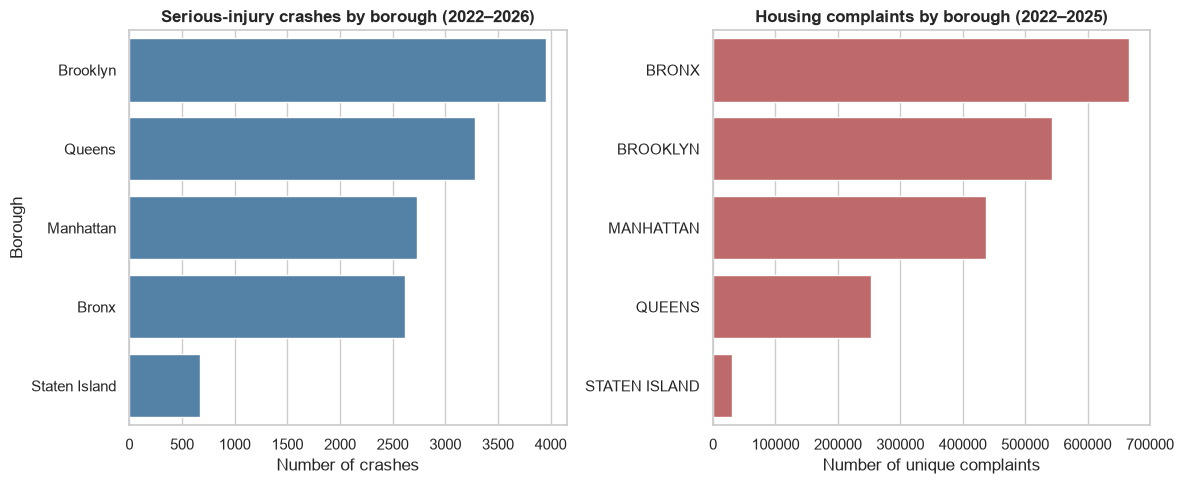

In [43]:
sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

crash_boro = df_transport['Crash Borough'].value_counts()
sns.barplot(x=crash_boro.values, y=crash_boro.index, ax=ax[0], color='steelblue')
ax[0].set_title('Serious-injury crashes by borough (2022–2026)', fontsize=12, weight='bold')
ax[0].set_xlabel('Number of crashes')
ax[0].set_ylabel('Borough')

hpd_boro = df_housing.groupby('borough', observed=True)['complaint_id'].nunique().sort_values(ascending=False)
sns.barplot(x=hpd_boro.values, y=hpd_boro.index, ax=ax[1], color='indianred')
ax[1].set_title('Housing complaints by borough (2022–2025)', fontsize=12, weight='bold')
ax[1].set_xlabel('Number of unique complaints')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

2. Top housing problem categories

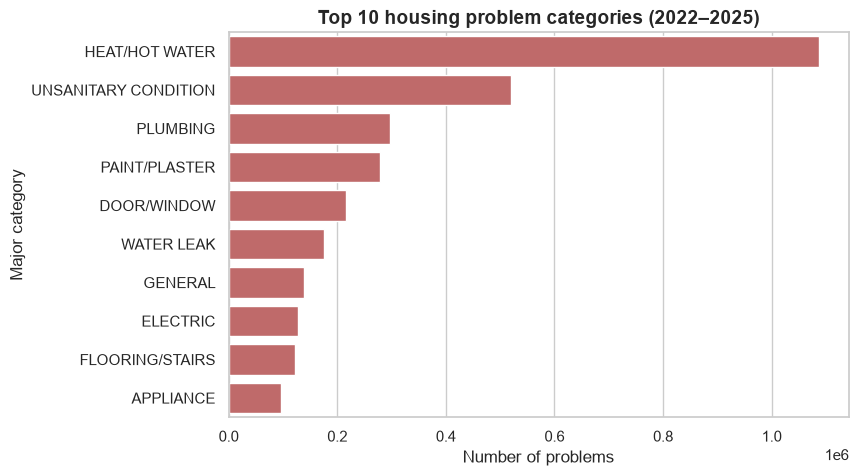

In [44]:
top_categories = df_housing['major_category'].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_categories.values, y=top_categories.index, color='indianred')
plt.title('Top 10 housing problem categories (2022–2025)', fontsize=14, weight='bold')
plt.xlabel('Number of problems')
plt.ylabel('Major category')
plt.show()

3. Injury distributions (outliers)

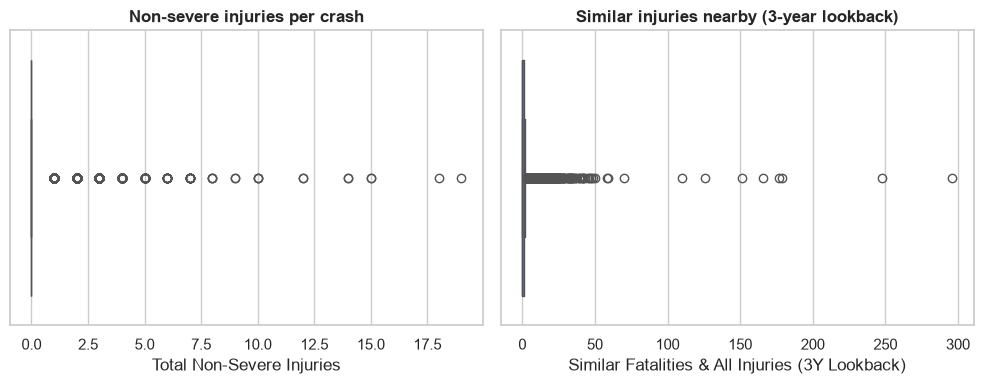

In [45]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
sns.boxplot(x=df_transport['Total Non-Severe Injuries'], ax=ax[0])
ax[0].set_title('Non-severe injuries per crash', fontsize=12, weight='bold')
sns.boxplot(x=df_transport['Similar Fatalities & All Injuries (3Y Lookback)'], ax=ax[1])
ax[1].set_title('Similar injuries nearby (3-year lookback)', fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

4. Monthly trend for both datasets

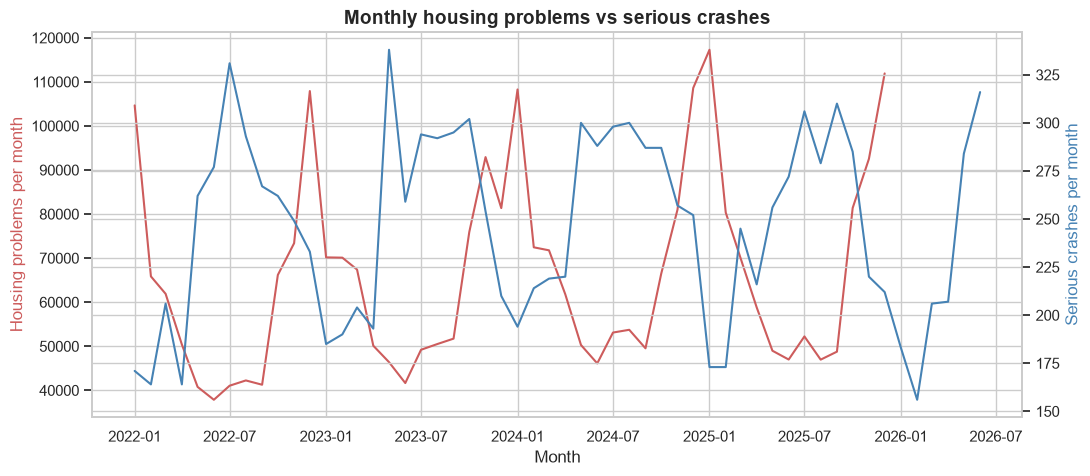

In [46]:
# Temporary date parsing just for this plot (proper conversion happens in cleaning)
crash_months = pd.to_datetime(df_transport['Crash Date'], format='%m/%d/%Y').dt.to_period('M').value_counts().sort_index()
hpd_months = pd.to_datetime(df_housing['received_date']).dt.to_period('M').value_counts().sort_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(hpd_months.index.to_timestamp(), hpd_months.values, color='indianred', label='Housing problems')
ax1.set_ylabel('Housing problems per month', color='indianred')
ax2 = ax1.twinx()
ax2.plot(crash_months.index.to_timestamp(), crash_months.values, color='steelblue', label='Serious crashes')
ax2.set_ylabel('Serious crashes per month', color='steelblue')
ax1.set_title('Monthly housing problems vs serious crashes', fontsize=14, weight='bold')
ax1.set_xlabel('Month')
plt.show()

### 3.3 EDA summary
- **SIRTA:** 444 fully empty rows; ZipCode missing in 41% (coordinates missing in only 21%); 8 columns are 70–92% empty; dates stored as text; ZIP stored as a number with invalid values (e.g. 10000); data runs to mid-2026.
- **HPD:** almost complete (post_code missing in 0.1%); invalid community_board values (0, >18); dates stored as text; several problems per complaint.
- **Both:** borough spelled differently (`Brooklyn` vs `BROOKLYN`).
- **Patterns:** borough rankings differ between the two datasets; complaints peak in winter while serious crashes peak in summer; injury outliers are real multi-casualty crashes and will be kept.

## 4. Pre-Integration Cleaning

## 5. Data Integration

## 6. Post-Integration Cleaning

## 7. Research Questions & Visualizations

## 8. Conclusions & Limitations

## 9. AI Prompt Log